In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

from extra_results import attach_shard_results

RESULTS_PATH = './results' if Path('./results').exists() else '../results'
assert Path(RESULTS_PATH).exists()

df = pd.read_csv(f'{RESULTS_PATH}/sbm_normalized_comparison.csv')

# TorusMDS_parallelogram was scored separately (compute_metrics.py --methods
# TorusMDS_parallelogram) into results/parallelogram/; attach it under the
# merged CSV's exp_idx (see extra_results.py). It was only run on the
# 100_1000 and 1000_3000 buckets.
PARALLELOGRAM = 'TorusMDS_parallelogram'
df = attach_shard_results(df, f'{RESULTS_PATH}/parallelogram', RESULTS_PATH)

# Compare every method on the same graphs: only those TorusMDS_parallelogram
# was run on (i.e. drops the 3000_10000 bucket). Set False to use all graphs
# for the other methods.
RESTRICT_TO_PARALLELOGRAM_GRAPHS = True
if RESTRICT_TO_PARALLELOGRAM_GRAPHS:
    df = df[df['exp_idx'].isin(df.loc[df['method'] == PARALLELOGRAM, 'exp_idx'])].reset_index(drop=True)

METHODS = [
    's_gd2', 'wrap_python',
    'TorusMDS_spectral_init', 'TorusMDS_smart_1x_scale2', 'TorusMDS_random_1x_scale2',
    'TorusMDS_parallelogram',
]
COLORS  = {
    's_gd2':                     '#4C72B0',
    'wrap_python':               '#55A868',
    'TorusMDS_spectral_init':    '#999999',
    'TorusMDS_smart_1x_scale2':  '#D65F66',
    'TorusMDS_random_1x_scale2': '#8172B2',
    'TorusMDS_parallelogram':    '#DD8452',
}
METRICS = ['stress',]
LABELS  = {
    'stress':     'Geodesic normalized stress',
    'distortion': 'Distortion',
    'sgs':        'SGS (Spearman rank corr.)',
    'np_score':   'Neighborhood preservation',
    't_embed':    'Embedding time (s)',
}

# TorusMDS_spectral_init is the spectral initialization alone, with no SGD
# refinement at all -- isolates how good the "smart" init is by itself.
# TorusMDS_{smart,random}_1x_scale2 are alpha_aspect runs that jointly learn
# alpha and the aspect ratio (r0, r1); smart/random is the init strategy
# (spectral vs none). Both use scale2 -- points initialized in the centered
# square [0.25, 0.75]^2, i.e. half the unit square's side length -- the other
# scale/1x variants were dropped from this comparison.
# TorusMDS_parallelogram learns alpha and a fully general parallelogram shape
# (side-length ratio and angle theta); its metrics use the exact parallelogram
# torus distance with the fitted theta.

data = {m: df[df['method'] == m] for m in METHODS}
print('--- overall ---')
print(df.groupby('method')[METRICS + ['t_embed']].agg(['mean', 'std']).round(4))
print()
print('--- graph counts (wrap_python is capped at n <= wrap-python-max-n, so it has fewer) ---')
print(df.groupby('method')['exp_idx'].nunique())

--- overall ---
                           stress           t_embed          
                             mean     std      mean       std
method                                                       
TorusMDS_parallelogram     0.3348  0.0068    8.2000    2.7266
TorusMDS_random_1x_scale2  0.3467  0.0131    5.3932    2.4323
TorusMDS_smart_1x_scale2   0.3461  0.0134    6.7556    3.7864
TorusMDS_spectral_init     0.3638  0.0141    0.0002    0.0000
s_gd2                      0.4097  0.0119    1.3363    1.8827
wrap_python                0.4218  0.0480  101.7605  158.1902

--- graph counts (wrap_python is capped at n <= wrap-python-max-n, so it has fewer) ---
method
TorusMDS_parallelogram       620
TorusMDS_random_1x_scale2    620
TorusMDS_smart_1x_scale2     620
TorusMDS_spectral_init       620
s_gd2                        620
wrap_python                  620
Name: exp_idx, dtype: int64


## Violin plots

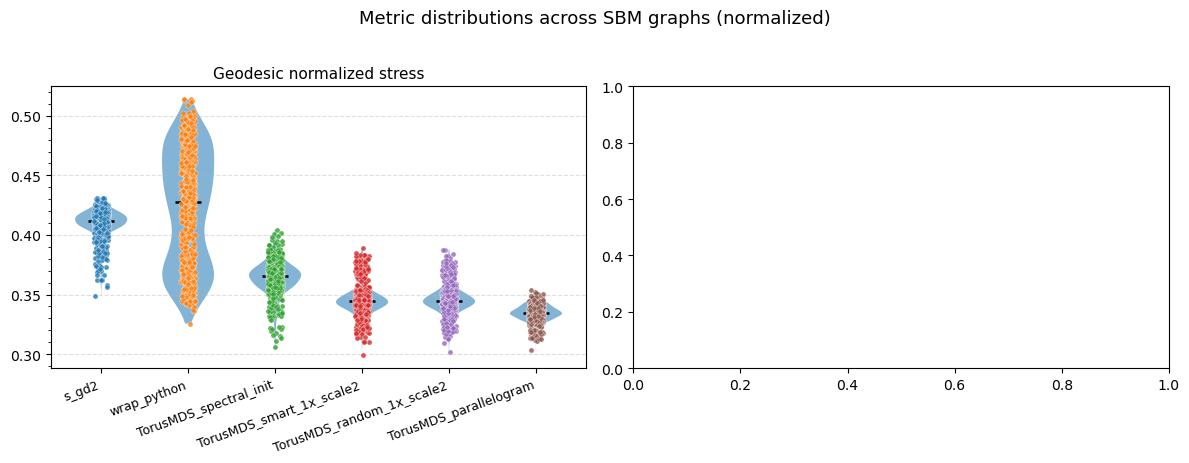

In [2]:
rng = np.random.default_rng(0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, metric in zip(axes, METRICS):
    parts = ax.violinplot(
        [data[m][metric].dropna().values for m in METHODS],
        positions=range(len(METHODS)),
        widths=0.6,
        showmedians=True,
        showextrema=False,
    )
    for pc, m in zip(parts['bodies'], METHODS):
        # pc.set_facecolor(COLORS[m])
        pc.set_alpha(0.55)
    parts['cmedians'].set_color('black')
    parts['cmedians'].set_linewidth(1.8)

    for xi, m in enumerate(METHODS):
        vals = data[m][metric].dropna().values
        jitter = rng.uniform(-0.08, 0.08, size=len(vals))
        ax.scatter(xi + jitter, vals, s=14, 
                #    color=COLORS[m],
                   edgecolors='white', linewidths=0.3, zorder=3, alpha=0.8)

    ax.set_xticks(range(len(METHODS)))
    ax.set_xticklabels(METHODS, fontsize=9, rotation=20, ha='right')
    ax.set_title(LABELS[metric], fontsize=11)
    ax.yaxis.set_minor_locator(mticker.AutoMinorLocator())
    ax.grid(axis='y', which='major', linestyle='--', alpha=0.4)

fig.suptitle('Metric distributions across SBM graphs (normalized)', fontsize=13, y=1.02)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/sbm_normalized_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## Metrics vs graph size n

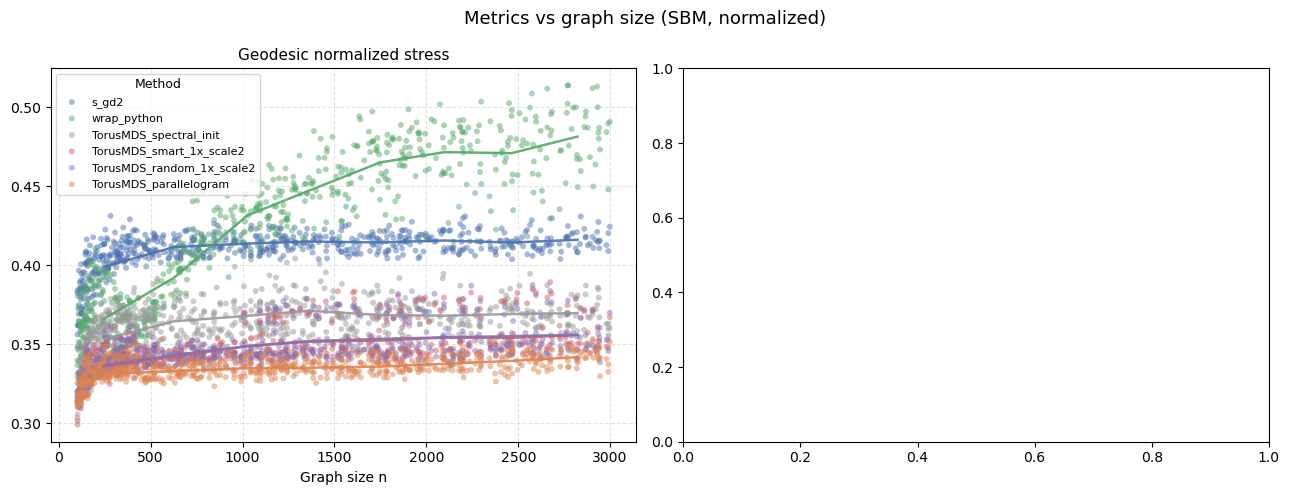

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metric in zip(axes, METRICS):
    for m in METHODS:
        d = data[m].sort_values('n')
        ax.scatter(d['n'], d[metric], s=18, color=COLORS[m],
                   alpha=0.5, label=m, edgecolors='none')
        bins = pd.cut(d['n'], bins=8)
        trend = d.groupby(bins, observed=True)[metric].mean()
        mids  = d.groupby(bins, observed=True)['n'].mean()
        ax.plot(mids.values, trend.values, color=COLORS[m], linewidth=1.8, alpha=0.9)

    ax.set_xlabel('Graph size n', fontsize=10)
    ax.set_title(LABELS[metric], fontsize=11)
    ax.grid(linestyle='--', alpha=0.35)

axes[0].legend(title='Method', fontsize=8, title_fontsize=9)
fig.suptitle('Metrics vs graph size (SBM, normalized)', fontsize=13)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/sbm_normalized_metrics_vs_n.png', dpi=150, bbox_inches='tight')
plt.show()

## Metrics vs number of blocks k

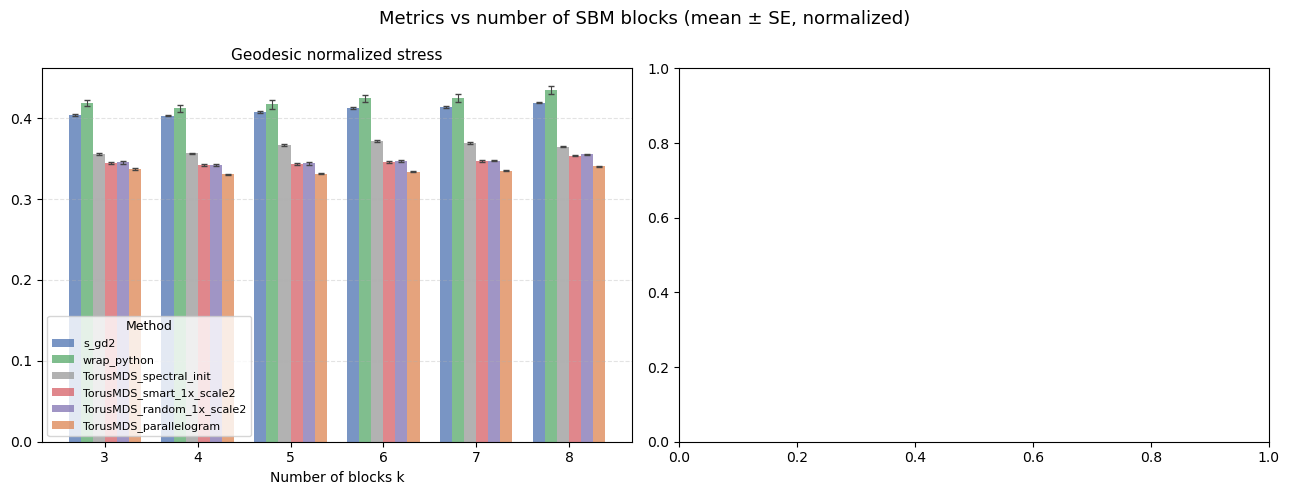

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
w = 0.13   # bar width
ks = sorted(df['k'].unique())

for ax, metric in zip(axes, METRICS):
    for xi, m in enumerate(METHODS):
        means = [data[m][data[m]['k'] == k][metric].mean() for k in ks]
        sems  = [data[m][data[m]['k'] == k][metric].sem()  for k in ks]
        offsets = np.array(ks) + (xi - (len(METHODS) - 1) / 2) * w
        ax.bar(offsets, means, width=w, color=COLORS[m],
               alpha=0.75, label=m, yerr=sems, capsize=2,
               error_kw=dict(elinewidth=0.8, ecolor='#444'))

    ax.set_xticks(ks)
    ax.set_xlabel('Number of blocks k', fontsize=10)
    ax.set_title(LABELS[metric], fontsize=11)
    ax.grid(axis='y', linestyle='--', alpha=0.35)

axes[0].legend(title='Method', fontsize=8, title_fontsize=9)
fig.suptitle('Metrics vs number of SBM blocks (mean ± SE, normalized)', fontsize=13)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/sbm_normalized_metrics_vs_k.png', dpi=150, bbox_inches='tight')
plt.show()

## Running time distributions

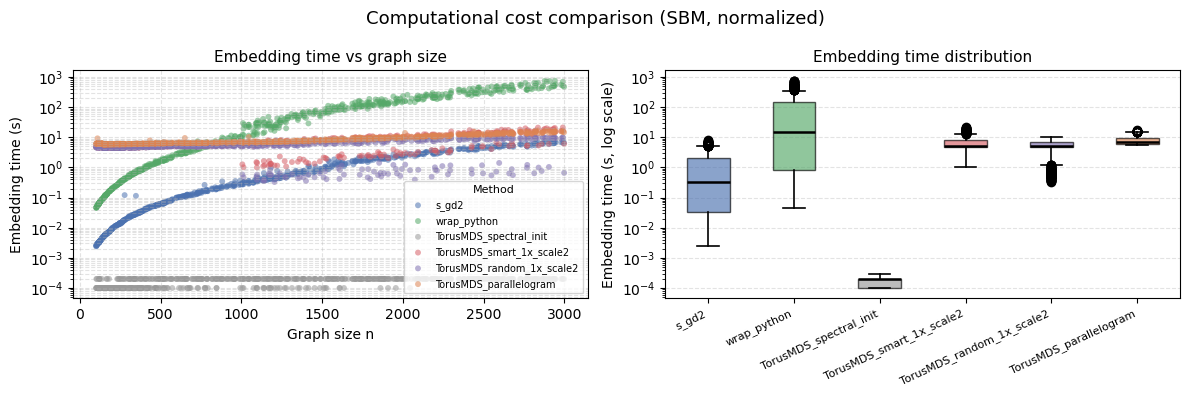

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
for m in METHODS:
    d = data[m]
    ax.scatter(d['n'], d['t_embed'], s=18, color=COLORS[m],
               alpha=0.55, label=m, edgecolors='none')
ax.set_xlabel('Graph size n', fontsize=10)
ax.set_ylabel('Embedding time (s)', fontsize=10)
ax.set_yscale('log')
ax.set_title('Embedding time vs graph size', fontsize=11)
ax.legend(title='Method', fontsize=7, title_fontsize=8)
ax.grid(linestyle='--', alpha=0.35, which='both')

ax = axes[1]
bp = ax.boxplot(
    [data[m]['t_embed'].values for m in METHODS],
    patch_artist=True,
    medianprops=dict(color='black', linewidth=1.8),
    whiskerprops=dict(linewidth=1.2),
    capprops=dict(linewidth=1.2),
)
for patch, m in zip(bp['boxes'], METHODS):
    patch.set_facecolor(COLORS[m])
    patch.set_alpha(0.65)
ax.set_yscale('log')
ax.set_xticks(range(1, len(METHODS) + 1))
ax.set_xticklabels(METHODS, fontsize=8, rotation=25, ha='right')
ax.set_ylabel('Embedding time (s, log scale)', fontsize=10)
ax.set_title('Embedding time distribution', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.35)
ax.yaxis.set_minor_locator(mticker.LogLocator(subs='all', numticks=10))

fig.suptitle('Computational cost comparison (SBM, normalized)', fontsize=13)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/sbm_normalized_timing.png', dpi=150, bbox_inches='tight')
plt.show()

## Runtime scatter comparison

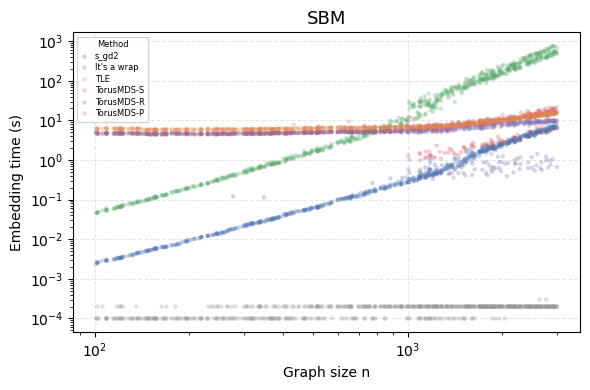

In [6]:
import seaborn as sns

METHOD_DISPLAY_NAMES = {
    's_gd2': 's_gd2',
    'wrap_python': "It's a wrap",
    'TorusMDS_spectral_init': 'TLE',
    'TorusMDS_smart_1x_scale2': 'TorusMDS-S',
    'TorusMDS_random_1x_scale2': 'TorusMDS-R',
    'TorusMDS_parallelogram': 'TorusMDS-P',
}
# Shared family markers, matching the runtime-scatter convention.
FAMILY_MARKERS = {'SBM': 'o', 'GRG': 'X', 'SuiteSparse': 's'}

def plot_runtime_scatter_comparison(df, methods, colors, family='SBM'):
    """Compare algorithm runtimes; method labels and family marker follow the shared convention."""
    plot_data = df[df['method'].isin(methods)].copy()

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.scatterplot(
        data=plot_data, x='n', y='t_embed',
        hue='method', hue_order=methods, palette=colors,
        marker=FAMILY_MARKERS[family], s=10, alpha=0.3, edgecolor='none', ax=ax,
    )

    handles, labels = ax.get_legend_handles_labels()
    labels = [METHOD_DISPLAY_NAMES.get(label, label) for label in labels]
    ax.legend(
        handles, labels, title='Method', loc='upper left',
        fontsize=6, title_fontsize=6, frameon=True, fancybox=False,
        borderpad=0.45, labelspacing=0.3, handlelength=0.9, handleheight=0.9,
    )

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Graph size n', fontsize=10)
    ax.set_ylabel('Embedding time (s)', fontsize=10)
    ax.set_title(family, fontsize=13)
    ax.grid(which='major', linestyle='--', alpha=0.3)
    fig.tight_layout()
    return fig, ax

fig, ax = plot_runtime_scatter_comparison(df, METHODS, COLORS)
fig.savefig(f'{RESULTS_PATH}/sbm_normalized_runtime_scatter_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

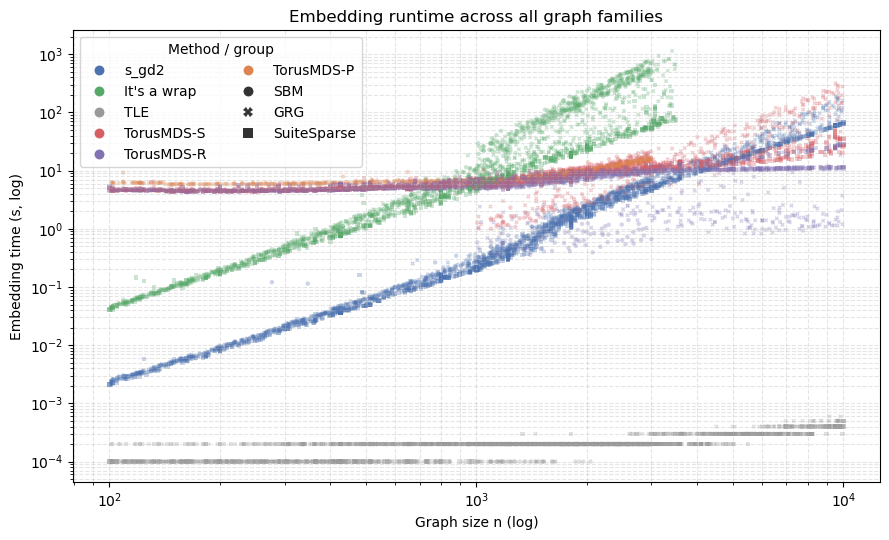

In [7]:
grg_df = pd.read_csv(f'{RESULTS_PATH}/grg_normalized_comparison.csv')
suitesparse_df = pd.read_csv(f'{RESULTS_PATH}/suitesparse_normalized_comparison.csv')

pooled = pd.concat(
    [
        grg_df.assign(graph_class='GRG'),
        df.assign(graph_class='SBM'),
        suitesparse_df.assign(graph_class='SuiteSparse'),
    ],
    ignore_index=True,
)
pooled = pooled[pooled['method'].isin(METHODS)].dropna(subset=['n', 't_embed'])

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(
    data=pooled, x='n', y='t_embed',
    hue='method', style='graph_class',
    hue_order=METHODS, style_order=['SBM', 'GRG', 'SuiteSparse'],
    palette=COLORS, markers=FAMILY_MARKERS,
    s=10, alpha=0.3, edgecolor='none', ax=ax,
)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Graph size n (log)')
ax.set_ylabel('Embedding time (s, log)')
ax.set_title('Embedding runtime across all graph families')
ax.grid(which='both', linestyle='--', alpha=0.32)

handles, labels = ax.get_legend_handles_labels()
legend_entries = [
    (handle, METHOD_DISPLAY_NAMES.get(label, label))
    for handle, label in zip(handles, labels)
    if label not in {'method', 'graph_class'}
]
for handle, label in legend_entries:
    handle.set_markersize(handle.get_markersize() * 2.25)
    handle.set_alpha(1)
handles, labels = zip(*legend_entries)
ax.legend(
    handles, labels, title='Method / group',
    bbox_to_anchor=(0.0, 1.0), loc='upper left', ncols=2,
)

fig.tight_layout()
fig.savefig(f'{RESULTS_PATH}/all_normalized_runtime_scatter_comparison.png',
            dpi=150, bbox_inches='tight')
plt.show()


## Summary table

In [8]:
summary = df.groupby('method')[METRICS + ['t_embed']].agg(['mean', 'median', 'std'])
summary.columns = [f'{m}_{s}' for m, s in summary.columns]
summary = summary.reindex(METHODS).round(4)
summary

,stress_mean,stress_median,stress_std,t_embed_mean,t_embed_median,t_embed_std
method,,,,,,
s_gd2,0.4097,0.4118,0.0119,1.3363,0.3378,1.8827
wrap_python,0.4218,0.4280,0.0480,101.7605,14.8478,158.1902
TorusMDS_spectral_init,0.3638,0.3652,0.0141,0.0002,0.0002,0.0000
TorusMDS_smart_1x_scale2,0.3461,0.3445,0.0134,6.7556,5.2181,3.7864
TorusMDS_random_1x_scale2,0.3467,0.3449,0.0131,5.3932,5.0404,2.4323
TorusMDS_parallelogram,0.3348,0.3348,0.0068,8.2000,6.9232,2.7266


## Percent change vs s_gd2 baseline

For each method, percent change is computed per matched graph instance against `s_gd2`
(`100 * (method - s_gd2) / s_gd2`), then averaged over the matched instances -- pairing on
`exp_idx` controls for per-graph difficulty, unlike comparing independent means. `wrap_python`
is capped at n <= wrap-python-max-n, so `n_matched` is much smaller for it; treat that column
with that caveat. For `stress`, negative values mean lower (better) stress than `s_gd2`; for
`np_score`, positive values mean better neighbourhood preservation; for `t_embed`, negative
values mean faster embedding.

In [9]:
def paired_pct_change(df, methods, baseline, id_col, metrics):
    """Per-instance percent change vs `baseline`, matched on `id_col`, then aggregated.

    Pairing on the same graph/matrix (rather than comparing independent means)
    controls for per-instance difficulty, which otherwise dominates the variance.
    """
    base = df[df['method'] == baseline].set_index(id_col)
    rows = {}
    for m in methods:
        if m == baseline:
            continue
        other = df[df['method'] == m].set_index(id_col)
        common = base.index.intersection(other.index)
        pct = {'n_matched': len(common)}
        for metric in metrics:
            vals = 100 * (other.loc[common, metric] - base.loc[common, metric]) / base.loc[common, metric]
            pct[f'{metric}_mean_pct'] = vals.mean()
            pct[f'{metric}_median_pct'] = vals.median()
        rows[m] = pct
    return pd.DataFrame(rows).T

pct_change = paired_pct_change(df, METHODS, 's_gd2', 'exp_idx', METRICS + ['t_embed'])
pct_change.round(2)

,n_matched,stress_mean_pct,stress_median_pct,t_embed_mean_pct,t_embed_median_pct
wrap_python,620.0,2.85,3.22,4818.95,4182.31
TorusMDS_spectral_init,620.0,-11.21,-11.39,-99.53,-99.95
TorusMDS_smart_1x_scale2,620.0,-15.51,-16.19,18125.77,1675.20
TorusMDS_random_1x_scale2,620.0,-15.36,-15.89,17910.62,1565.54
TorusMDS_parallelogram,620.0,-18.26,-18.45,23501.26,1996.98


### Percent-change distributions (strip plot)

Same paired comparison as above, shown as the full per-graph distribution rather than a single
summary number. Each dot is one matched graph; the black tick marks the median. Methods with
fewer than 5 matched instances vs. `s_gd2` are omitted.

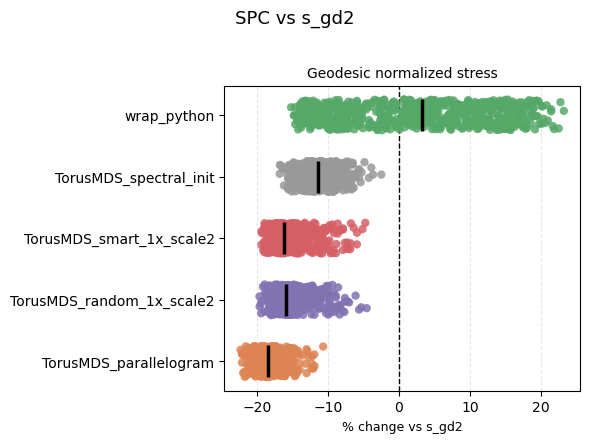

In [10]:
def paired_pct_change_long(df, methods, baseline, id_col, metrics, extra_cols=None):
    """Long-form per-instance percent change vs `baseline`, matched on `id_col`."""
    extra_cols = extra_cols or []
    base = df[df['method'] == baseline].set_index(id_col)
    frames = []
    for m in methods:
        if m == baseline:
            continue
        other = df[df['method'] == m].set_index(id_col)
        common = base.index.intersection(other.index)
        if len(common) == 0:
            continue
        for metric in metrics:
            pct = 100 * (other.loc[common, metric] - base.loc[common, metric]) / base.loc[common, metric]
            frame = pd.DataFrame({'method': m, 'metric': metric, id_col: common, 'pct_change': pct.values})
            for col in extra_cols:
                frame[col] = base.loc[common, col].values
            frames.append(frame)
    return pd.concat(frames, ignore_index=True)


def bootstrap_median_ci(vals, n_boot=2000, ci=95, seed=0):
    rng = np.random.default_rng(seed)
    vals = np.asarray(vals, dtype=float)
    boots = rng.choice(vals, size=(n_boot, len(vals)), replace=True)
    boot_medians = np.median(boots, axis=1)
    lo, hi = np.percentile(boot_medians, [(100 - ci) / 2, 100 - (100 - ci) / 2])
    return np.median(vals), lo, hi


MIN_N_FOR_DIST = 5  # below this a histogram/CI isn't meaningful (e.g. wrap_python's capped sample)
_methods_no_base = [m for m in METHODS if m != 's_gd2']
_n_matched = {
    m: len(set(df[df['method'] == m]['exp_idx']) & set(df[df['method'] == 's_gd2']['exp_idx']))
    for m in _methods_no_base
}
plot_methods = [m for m in _methods_no_base if _n_matched[m] >= MIN_N_FOR_DIST]
_skipped = [m for m in _methods_no_base if m not in plot_methods]
if _skipped:
    print(f"Skipping {_skipped} (fewer than {MIN_N_FOR_DIST} matched instances vs s_gd2)")

pct_long = paired_pct_change_long(df, METHODS, 's_gd2', 'exp_idx', METRICS)

import seaborn as sns

groups = [None]
palette = {m: COLORS[m] for m in plot_methods}
fig, axes = plt.subplots(
    1, len(METRICS),
    figsize=(6 * len(METRICS), 0.6 * len(plot_methods) + 1.3 * 1),
    squeeze=False,
)
for gi, gt in enumerate(groups):
    for mi, metric in enumerate(METRICS):
        ax = axes[gi][mi]
        sub = pct_long[pct_long['metric'] == metric]
        
        sub = sub[sub['method'].isin(plot_methods)]
        sns.stripplot(
            data=sub, x='pct_change', y='method', order=plot_methods, hue='method',
            hue_order=plot_methods, palette=palette, size=6, alpha=0.85, jitter=0.25,
            ax=ax, legend=False,
        )
        for yi, m in enumerate(plot_methods):
            vals = sub[sub['method'] == m]['pct_change'].dropna().values
            if len(vals) == 0:
                continue
            ax.scatter(np.median(vals), yi, marker='|', s=500, linewidths=2.5,
                       color='black', zorder=5)
        ax.axvline(0, color='black', linestyle='--', linewidth=1)
        ax.set_title(LABELS[metric], fontsize=10)
        ax.set_xlabel('% change vs s_gd2', fontsize=9)
        ax.set_ylabel('')
        ax.grid(axis='x', linestyle='--', alpha=0.3)
fig.suptitle(
    'SPC vs s_gd2',
    fontsize=13, y=1.02,
)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/sbm_normalized_pct_change_strip.png', dpi=150, bbox_inches='tight')
plt.show()

### Percent-change: median with 95% bootstrap CI

Bootstrap (2000 resamples) 95% CI on the median paired percent change. This is the number to
quote in the paper if you want a single point estimate with uncertainty rather than reporting the
mean, which the earlier table shows is skewed by a few outlier graphs.

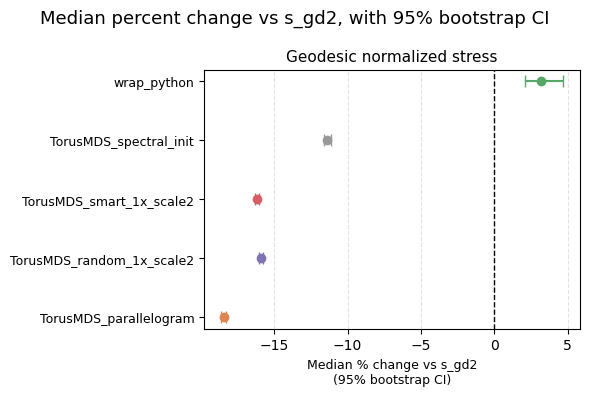

In [11]:
fig, axes = plt.subplots(1, len(METRICS), figsize=(6 * len(METRICS), 0.5 * len(plot_methods) + 1.5 * 1), squeeze=False)
for gi, gt in enumerate(groups):
    for mi, metric in enumerate(METRICS):
        ax = axes[gi][mi]
        sub = pct_long[pct_long['metric'] == metric]
        
        for yi, m in enumerate(plot_methods):
            vals = sub[sub['method'] == m]['pct_change'].dropna().values
            if len(vals) == 0:
                continue
            med, lo, hi = bootstrap_median_ci(vals)
            ax.errorbar(med, yi, xerr=[[med - lo], [hi - med]], fmt='o', color=COLORS[m], capsize=4, markersize=6)
        ax.axvline(0, color='black', linestyle='--', linewidth=1)
        ax.set_yticks(range(len(plot_methods)))
        ax.set_yticklabels(plot_methods, fontsize=9)
        ax.invert_yaxis()
        ax.set_xlabel('Median % change vs s_gd2\n(95% bootstrap CI)', fontsize=9)
        ax.set_title(LABELS[metric], fontsize=11)
        ax.grid(axis='x', linestyle='--', alpha=0.35)
fig.suptitle('Median percent change vs s_gd2, with 95% bootstrap CI', fontsize=13)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/sbm_normalized_pct_change_ci.png', dpi=150, bbox_inches='tight')
plt.show()

### Symmetric percent change (SPC) distributions (strip plot)

SPC = (method - s_gd2) / max(|method|, |s_gd2|), scaled to a percentage -- unlike the plain
percent change above, it is bounded to [-100, 100] regardless of how small the baseline is.
Same per-instance layout as the percent-change strip plot above.

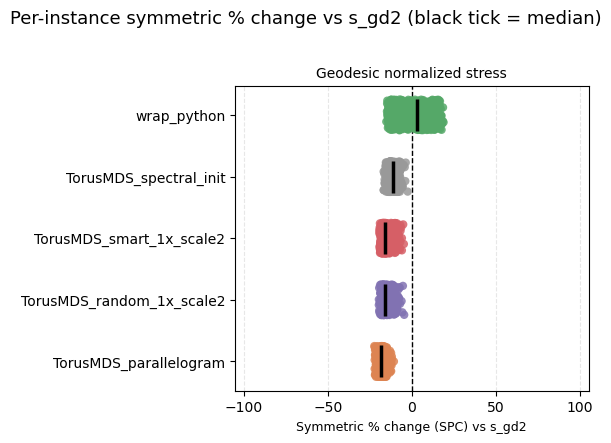

In [12]:
def paired_spc_long(df, methods, baseline, id_col, metrics, extra_cols=None):
    """Per-instance symmetric percent change vs `baseline`, matched on `id_col`.

    SPC = (A - B) / max(|A|, |B|), scaled to a percentage. Bounded to [-100, 100]
    (our metrics are all non-negative), unlike plain percent change, which blows up
    whenever the baseline is small.
    """
    extra_cols = extra_cols or []
    base = df[df['method'] == baseline].set_index(id_col)
    frames = []
    for m in methods:
        if m == baseline:
            continue
        other = df[df['method'] == m].set_index(id_col)
        common = base.index.intersection(other.index)
        if len(common) == 0:
            continue
        for metric in metrics:
            a = other.loc[common, metric]
            b = base.loc[common, metric]
            denom = np.maximum(a.abs(), b.abs())
            spc = 100 * (a - b) / denom
            frame = pd.DataFrame({'method': m, 'metric': metric, id_col: common, 'spc': spc.values})
            for col in extra_cols:
                frame[col] = base.loc[common, col].values
            frames.append(frame)
    return pd.concat(frames, ignore_index=True)


spc_long = paired_spc_long(df, METHODS, 's_gd2', 'exp_idx', METRICS)

fig, axes = plt.subplots(
    1, len(METRICS),
    figsize=(6 * len(METRICS), 0.6 * len(plot_methods) + 1.3 * 1),
    squeeze=False,
)
for gi, gt in enumerate(groups):
    for mi, metric in enumerate(METRICS):
        ax = axes[gi][mi]
        sub = spc_long[spc_long['metric'] == metric]
        
        sub = sub[sub['method'].isin(plot_methods)]
        sns.stripplot(
            data=sub, x='spc', y='method', order=plot_methods, hue='method',
            hue_order=plot_methods, palette=palette, size=6, alpha=0.85, jitter=0.25,
            ax=ax, legend=False,
        )
        for yi, m in enumerate(plot_methods):
            vals = sub[sub['method'] == m]['spc'].dropna().values
            if len(vals) == 0:
                continue
            ax.scatter(np.median(vals), yi, marker='|', s=500, linewidths=2.5,
                       color='black', zorder=5)
        ax.axvline(0, color='black', linestyle='--', linewidth=1)
        ax.set_xlim(-105, 105)
        ax.set_title(LABELS[metric], fontsize=10)
        ax.set_xlabel('Symmetric % change (SPC) vs s_gd2', fontsize=9)
        ax.set_ylabel('')
        ax.grid(axis='x', linestyle='--', alpha=0.3)
fig.suptitle(
    'Per-instance symmetric % change vs s_gd2 (black tick = median)',
    fontsize=13, y=1.02,
)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/sbm_normalized_spc_strip.png', dpi=150, bbox_inches='tight')
plt.show()

### SPC: median with 95% bootstrap CI

Because SPC is bounded, its distribution is far less outlier-driven than the plain percent
change's -- the mean and median are much closer together here (compare to the earlier table).
Median is still shown for direct visual consistency with the percent-change CI plot above.

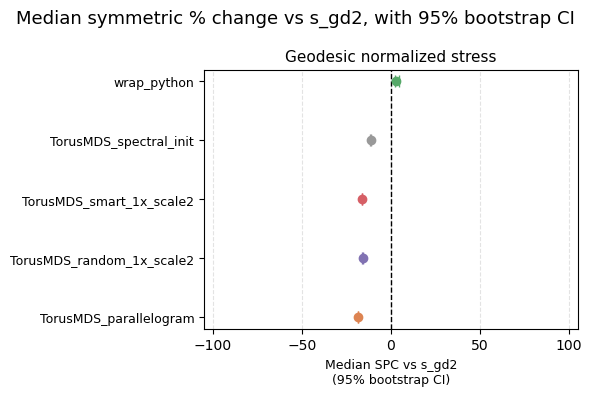

In [13]:
fig, axes = plt.subplots(
    1, len(METRICS),
    figsize=(6 * len(METRICS), 0.5 * len(plot_methods) + 1.5 * 1),
    squeeze=False,
)
for gi, gt in enumerate(groups):
    for mi, metric in enumerate(METRICS):
        ax = axes[gi][mi]
        sub = spc_long[spc_long['metric'] == metric]
        
        for yi, m in enumerate(plot_methods):
            vals = sub[sub['method'] == m]['spc'].dropna().values
            if len(vals) == 0:
                continue
            med, lo, hi = bootstrap_median_ci(vals)
            ax.errorbar(med, yi, xerr=[[med - lo], [hi - med]], fmt='o', color=COLORS[m], capsize=4, markersize=6)
        ax.axvline(0, color='black', linestyle='--', linewidth=1)
        ax.set_yticks(range(len(plot_methods)))
        ax.set_yticklabels(plot_methods, fontsize=9)
        ax.invert_yaxis()
        ax.set_xlim(-105, 105)
        ax.set_xlabel('Median SPC vs s_gd2\n(95% bootstrap CI)', fontsize=9)
        ax.set_title(LABELS[metric], fontsize=11)
        ax.grid(axis='x', linestyle='--', alpha=0.35)
fig.suptitle(
    'Median symmetric % change vs s_gd2, with 95% bootstrap CI',
    fontsize=13,
)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/sbm_normalized_spc_ci.png', dpi=150, bbox_inches='tight')
plt.show()

### SPC vs `wrap_python`: median with 95% bootstrap CI

Same SPC definition as above, but here `wrap_python` is the baseline instead of `s_gd2` --
useful since `wrap_python` is itself a competing wrap-aware layout method, not just a
reference baseline. Note `wrap_python`'s own `n <= wrap-python-max-n` cap now bounds every
method's `n_matched` here (not just `wrap_python`'s row in the mean-based tables above),
since the paired comparison can only use graphs `wrap_python` actually has a layout for.

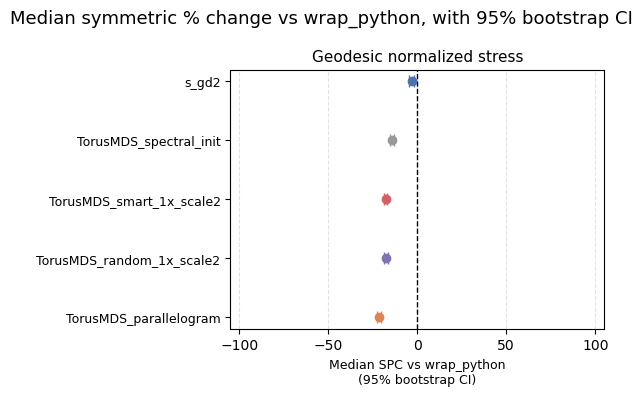

In [14]:
_methods_no_wrap = [m for m in METHODS if m != 'wrap_python']
_n_matched_wrap = {
    m: len(set(df[df['method'] == m]['exp_idx']) & set(df[df['method'] == 'wrap_python']['exp_idx']))
    for m in _methods_no_wrap
}
plot_methods_wrap = [m for m in _methods_no_wrap if _n_matched_wrap[m] >= MIN_N_FOR_DIST]
_skipped_wrap = [m for m in _methods_no_wrap if m not in plot_methods_wrap]
if _skipped_wrap:
    print(f"Skipping {_skipped_wrap} (fewer than {MIN_N_FOR_DIST} matched instances vs wrap_python)")

spc_long_wrap = paired_spc_long(df, METHODS, 'wrap_python', 'exp_idx', METRICS)

fig, axes = plt.subplots(
    1, len(METRICS),
    figsize=(6 * len(METRICS), 0.5 * len(plot_methods_wrap) + 1.5 * 1),
    squeeze=False,
)
for gi, gt in enumerate(groups):
    for mi, metric in enumerate(METRICS):
        ax = axes[gi][mi]
        sub = spc_long_wrap[spc_long_wrap['metric'] == metric]

        for yi, m in enumerate(plot_methods_wrap):
            vals = sub[sub['method'] == m]['spc'].dropna().values
            if len(vals) == 0:
                continue
            med, lo, hi = bootstrap_median_ci(vals)
            ax.errorbar(med, yi, xerr=[[med - lo], [hi - med]], fmt='o', color=COLORS[m], capsize=4, markersize=6)
        ax.axvline(0, color='black', linestyle='--', linewidth=1)
        ax.set_yticks(range(len(plot_methods_wrap)))
        ax.set_yticklabels(plot_methods_wrap, fontsize=9)
        ax.invert_yaxis()
        ax.set_xlim(-105, 105)
        ax.set_xlabel('Median SPC vs wrap_python\n(95% bootstrap CI)', fontsize=9)
        ax.set_title(LABELS[metric], fontsize=11)
        ax.grid(axis='x', linestyle='--', alpha=0.35)
fig.suptitle(
    'Median symmetric % change vs wrap_python, with 95% bootstrap CI',
    fontsize=13,
)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/sbm_normalized_spc_ci_vs_wrap_python.png', dpi=150, bbox_inches='tight')
plt.show()


## Runtime: percent change vs s_gd2

The same paired-instance approach as the accuracy metrics above, applied to embedding time.

### Embedding-time percent change (strip plot)

Runtime ratios span orders of magnitude (`s_gd2` vs. `wrap_python` vs. TorusMDS's SGD cost
differ substantially), so the x-axis uses a symmetric log scale (linear within ±10%, log beyond).
Same per-instance layout as the accuracy strip plots above.

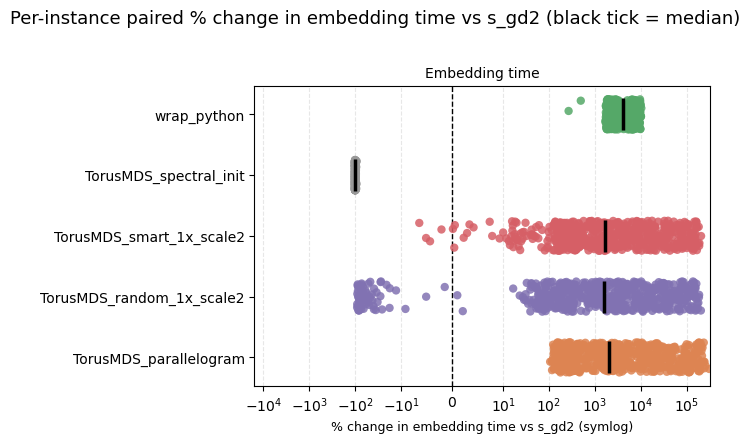

In [15]:
RUNTIME_METRICS = ['t_embed']
pct_long_time = paired_pct_change_long(df, METHODS, 's_gd2', 'exp_idx', RUNTIME_METRICS)

fig, axes = plt.subplots(
    1, 1, figsize=(7, 0.6 * len(plot_methods) + 1.3 * 1), squeeze=False,
)
for gi, gt in enumerate(groups):
    ax = axes[gi][0]
    sub = pct_long_time[pct_long_time['metric'] == 't_embed']
    
    sub = sub[sub['method'].isin(plot_methods)]
    sns.stripplot(
        data=sub, x='pct_change', y='method', order=plot_methods, hue='method',
        hue_order=plot_methods, palette=palette, size=6, alpha=0.85, jitter=0.25,
        ax=ax, legend=False,
    )
    for yi, m in enumerate(plot_methods):
        vals = sub[sub['method'] == m]['pct_change'].dropna().values
        if len(vals) == 0:
            continue
        ax.scatter(np.median(vals), yi, marker='|', s=500, linewidths=2.5, color='black', zorder=5)
    ax.axvline(0, color='black', linestyle='--', linewidth=1)
    ax.set_xscale('symlog', linthresh=10)
    ax.set_title('Embedding time', fontsize=10)
    ax.set_xlabel('% change in embedding time vs s_gd2 (symlog)', fontsize=9)
    ax.set_ylabel('')
    ax.grid(axis='x', linestyle='--', alpha=0.3)
fig.suptitle(
    'Per-instance paired % change in embedding time vs s_gd2 (black tick = median)',
    fontsize=13, y=1.02,
)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/sbm_normalized_time_pct_change_strip.png', dpi=150, bbox_inches='tight')
plt.show()

### Embedding-time percent change: median with 95% bootstrap CI

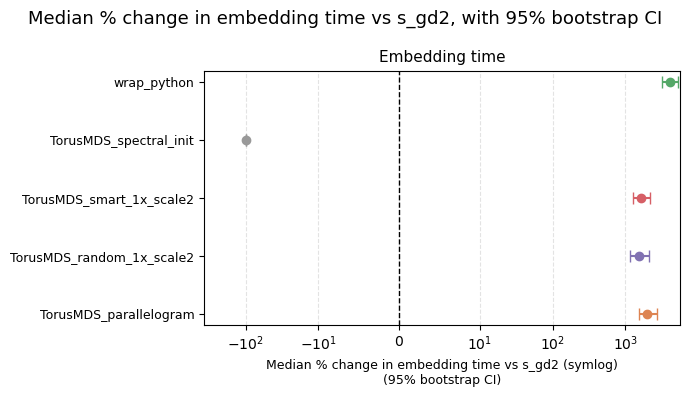

In [16]:
fig, axes = plt.subplots(
    1, 1, figsize=(7, 0.5 * len(plot_methods) + 1.5 * 1), squeeze=False,
)
for gi, gt in enumerate(groups):
    ax = axes[gi][0]
    sub = pct_long_time[pct_long_time['metric'] == 't_embed']
    
    for yi, m in enumerate(plot_methods):
        vals = sub[sub['method'] == m]['pct_change'].dropna().values
        if len(vals) == 0:
            continue
        med, lo, hi = bootstrap_median_ci(vals)
        ax.errorbar(med, yi, xerr=[[med - lo], [hi - med]], fmt='o', color=COLORS[m], capsize=4, markersize=6)
    ax.axvline(0, color='black', linestyle='--', linewidth=1)
    ax.set_xscale('symlog', linthresh=10)
    ax.set_yticks(range(len(plot_methods)))
    ax.set_yticklabels(plot_methods, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlabel('Median % change in embedding time vs s_gd2 (symlog)\n(95% bootstrap CI)', fontsize=9)
    ax.set_title('Embedding time', fontsize=11)
    ax.grid(axis='x', linestyle='--', alpha=0.35)
fig.suptitle(
    'Median % change in embedding time vs s_gd2, with 95% bootstrap CI',
    fontsize=13,
)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/sbm_normalized_time_pct_change_ci.png', dpi=150, bbox_inches='tight')
plt.show()

### Embedding-time symmetric percent change (SPC) (strip plot)

Same SPC definition as for the accuracy metrics, bounded to [-100, 100] -- useful here since
runtime's plain percent change is heavy-tailed enough to need a log axis above.

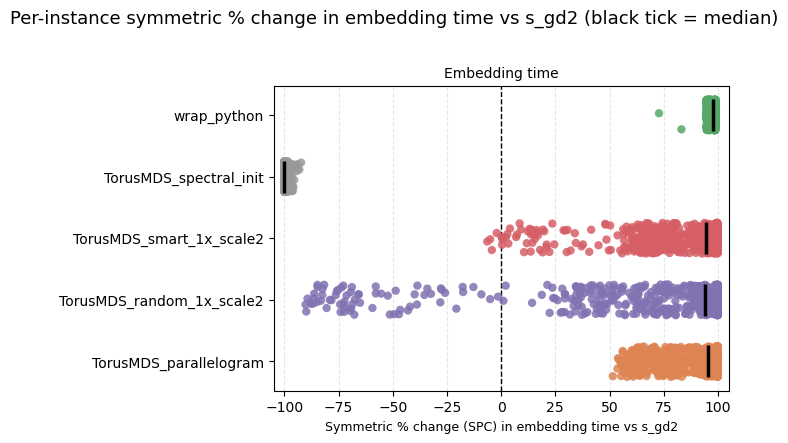

In [17]:
spc_long_time = paired_spc_long(df, METHODS, 's_gd2', 'exp_idx', RUNTIME_METRICS)

fig, axes = plt.subplots(
    1, 1, figsize=(7, 0.6 * len(plot_methods) + 1.3 * 1), squeeze=False,
)
for gi, gt in enumerate(groups):
    ax = axes[gi][0]
    sub = spc_long_time[spc_long_time['metric'] == 't_embed']
    
    sub = sub[sub['method'].isin(plot_methods)]
    sns.stripplot(
        data=sub, x='spc', y='method', order=plot_methods, hue='method',
        hue_order=plot_methods, palette=palette, size=6, alpha=0.85, jitter=0.25,
        ax=ax, legend=False,
    )
    for yi, m in enumerate(plot_methods):
        vals = sub[sub['method'] == m]['spc'].dropna().values
        if len(vals) == 0:
            continue
        ax.scatter(np.median(vals), yi, marker='|', s=500, linewidths=2.5, color='black', zorder=5)
    ax.axvline(0, color='black', linestyle='--', linewidth=1)
    ax.set_xlim(-105, 105)
    ax.set_title('Embedding time', fontsize=10)
    ax.set_xlabel('Symmetric % change (SPC) in embedding time vs s_gd2', fontsize=9)
    ax.set_ylabel('')
    ax.grid(axis='x', linestyle='--', alpha=0.3)
fig.suptitle(
    'Per-instance symmetric % change in embedding time vs s_gd2 (black tick = median)',
    fontsize=13, y=1.02,
)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/sbm_normalized_time_spc_strip.png', dpi=150, bbox_inches='tight')
plt.show()

### Embedding-time SPC: median with 95% bootstrap CI

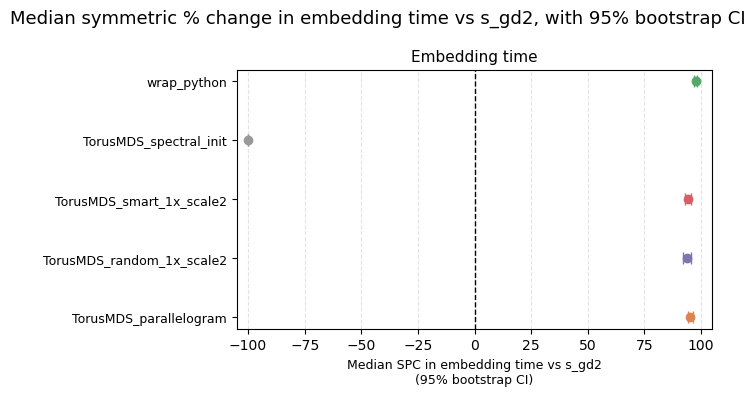

In [18]:
fig, axes = plt.subplots(
    1, 1, figsize=(7, 0.5 * len(plot_methods) + 1.5 * 1), squeeze=False,
)
for gi, gt in enumerate(groups):
    ax = axes[gi][0]
    sub = spc_long_time[spc_long_time['metric'] == 't_embed']
    
    for yi, m in enumerate(plot_methods):
        vals = sub[sub['method'] == m]['spc'].dropna().values
        if len(vals) == 0:
            continue
        med, lo, hi = bootstrap_median_ci(vals)
        ax.errorbar(med, yi, xerr=[[med - lo], [hi - med]], fmt='o', color=COLORS[m], capsize=4, markersize=6)
    ax.axvline(0, color='black', linestyle='--', linewidth=1)
    ax.set_xlim(-105, 105)
    ax.set_yticks(range(len(plot_methods)))
    ax.set_yticklabels(plot_methods, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlabel('Median SPC in embedding time vs s_gd2\n(95% bootstrap CI)', fontsize=9)
    ax.set_title('Embedding time', fontsize=11)
    ax.grid(axis='x', linestyle='--', alpha=0.35)
fig.suptitle(
    'Median symmetric % change in embedding time vs s_gd2, with 95% bootstrap CI',
    fontsize=13,
)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/sbm_normalized_time_spc_ci.png', dpi=150, bbox_inches='tight')
plt.show()

### Embedding-time SPC vs `wrap_python`: median with 95% bootstrap CI

Same as the embedding-time SPC-CI plot above, but baselined against `wrap_python` instead
of `s_gd2`.

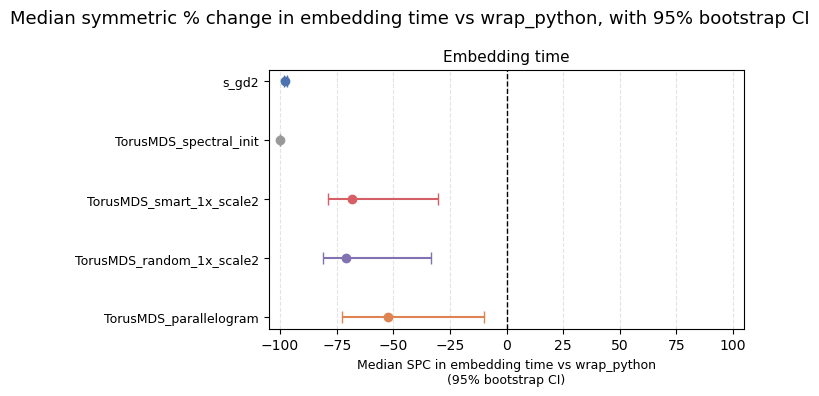

In [19]:
spc_long_time_wrap = paired_spc_long(df, METHODS, 'wrap_python', 'exp_idx', RUNTIME_METRICS)

fig, axes = plt.subplots(
    1, 1, figsize=(7, 0.5 * len(plot_methods_wrap) + 1.5 * 1), squeeze=False,
)
for gi, gt in enumerate(groups):
    ax = axes[gi][0]
    sub = spc_long_time_wrap[spc_long_time_wrap['metric'] == 't_embed']

    for yi, m in enumerate(plot_methods_wrap):
        vals = sub[sub['method'] == m]['spc'].dropna().values
        if len(vals) == 0:
            continue
        med, lo, hi = bootstrap_median_ci(vals)
        ax.errorbar(med, yi, xerr=[[med - lo], [hi - med]], fmt='o', color=COLORS[m], capsize=4, markersize=6)
    ax.axvline(0, color='black', linestyle='--', linewidth=1)
    ax.set_xlim(-105, 105)
    ax.set_yticks(range(len(plot_methods_wrap)))
    ax.set_yticklabels(plot_methods_wrap, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlabel('Median SPC in embedding time vs wrap_python\n(95% bootstrap CI)', fontsize=9)
    ax.set_title('Embedding time', fontsize=11)
    ax.grid(axis='x', linestyle='--', alpha=0.35)
fig.suptitle(
    'Median symmetric % change in embedding time vs wrap_python, with 95% bootstrap CI',
    fontsize=13,
)
fig.tight_layout()
plt.savefig(f'{RESULTS_PATH}/sbm_normalized_time_spc_ci_vs_wrap_python.png', dpi=150, bbox_inches='tight')
plt.show()
